In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Netflix dataset
df = pd.read_csv('netflix_titles.csv')

# View the first 5 rows
df.head()

Matplotlib is building the font cache; this may take a moment.


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
# Check dataset structure and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [3]:
# Fill missing categorical text with 'Unknown'
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Drop the tiny number of rows missing 'date_added' or 'rating'
df = df.dropna(subset=['date_added', 'rating'])

# Convert 'date_added' to datetime format and extract the year
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['year_added'] = df['date_added'].dt.year

# Check remaining missing values
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        3
listed_in       0
description     0
year_added      0
dtype: int64

### 1. Content Type Breakdown
**Insight:** Movies dominate the Netflix platform, accounting for approximately 70% of total titles (6,129 Movies vs. 2,664 TV Shows).

type
Movie      6129
TV Show    2664
Name: count, dtype: int64


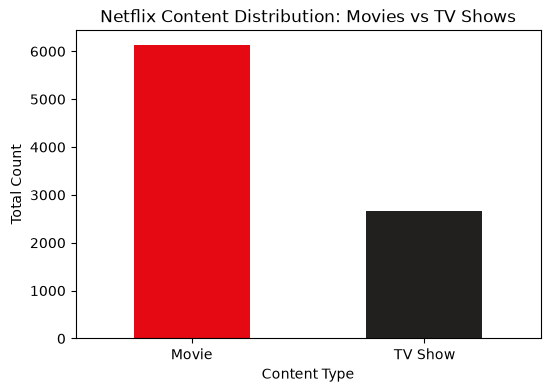

In [4]:
# Count the number of Movies vs TV Shows
type_counts = df['type'].value_counts()
print(type_counts)

# Create a bar chart to visualize the split
plt.figure(figsize=(6, 4))
type_counts.plot(kind='bar', color=['#E50914', '#221F1F'])
plt.title('Netflix Content Distribution: Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Total Count')
plt.xticks(rotation=0)
plt.show()

### 2. Content Growth Trends
**Insight:** Content additions experienced exponential growth starting in 2016, reaching a peak in **2019** with over 1,400 movies added before tapering off post-2020.

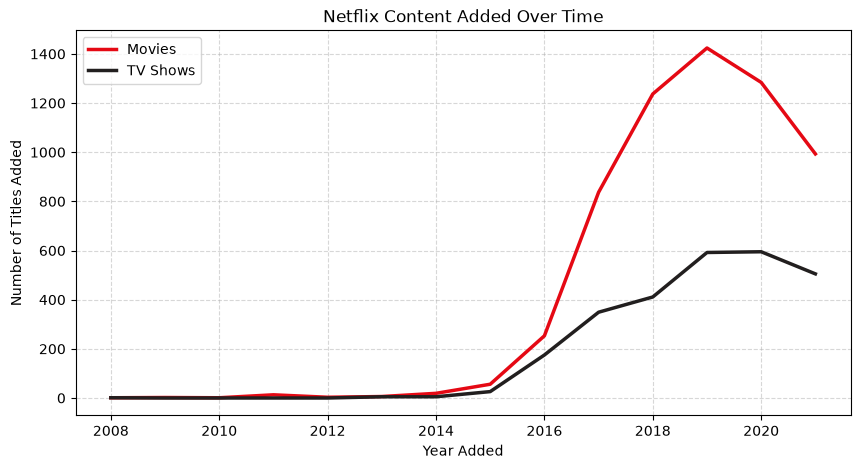

In [5]:
# Group data by year_added and type
content_by_year = df.groupby(['year_added', 'type']).size().unstack().fillna(0)

# Plot trend lines
plt.figure(figsize=(10, 5))
plt.plot(content_by_year.index, content_by_year['Movie'], label='Movies', color='#E50914', linewidth=2.5)
plt.plot(content_by_year.index, content_by_year['TV Show'], label='TV Shows', color='#221F1F', linewidth=2.5)

plt.title('Netflix Content Added Over Time')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles Added')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 3. Top Content Producing Countries
**Insight:** The **United States** leads in total content production, followed by **India** and the **United Kingdom**, reflecting Netflix's strategic expansion into international markets like Bollywood.

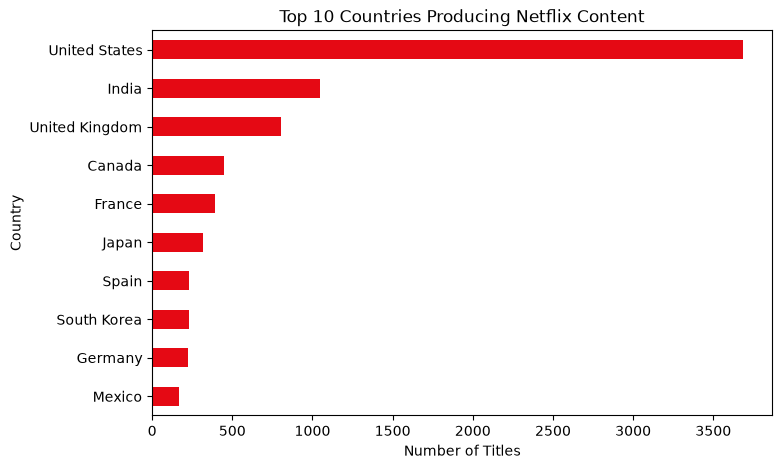

In [6]:
# Separate multiple countries and count top 10
top_countries = df['country'].str.split(', ').explode().value_counts()

# Remove 'Unknown' from the top ranking
if 'Unknown' in top_countries:
    top_countries = top_countries.drop('Unknown')

# Get the top 10 countries
top_10 = top_countries.head(10)

# Plot horizontal bar chart
plt.figure(figsize=(8, 5))
top_10.sort_values().plot(kind='barh', color='#E50914')
plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()


### 3. Top Content Producing Countries
**Insight:** The **United States** leads in total content production, followed by **India** and the **United Kingdom**, reflecting Netflix's strategic expansion into international markets like Bollywood.

### 4. Dominant Genres
**Insight:** **International Movies**, **Dramas**, and **Comedies** represent the top genres on the platform, emphasizing the global nature of Netflix's catalog.

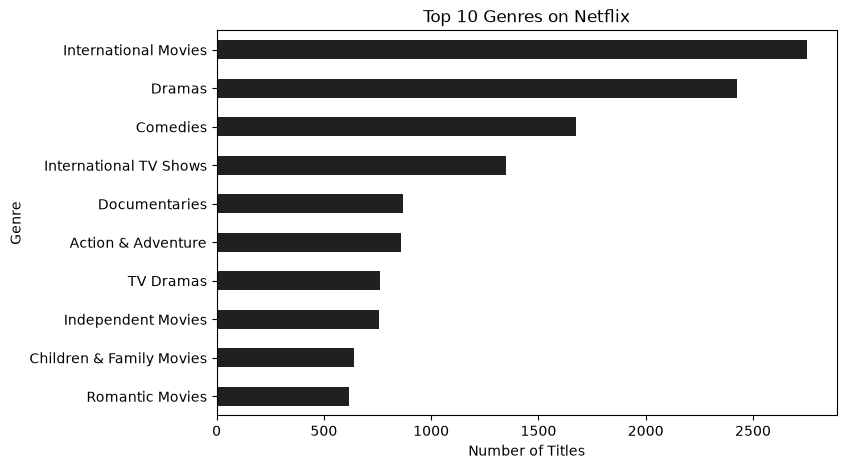

In [7]:
# Separate genres and get top 10
top_genres = df['listed_in'].str.split(', ').explode().value_counts().head(10)

# Plot horizontal bar chart
plt.figure(figsize=(8, 5))
top_genres.sort_values().plot(kind='barh', color='#221F1F')
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

### 5. Audience Rating Distribution
**Insight:** **TV-MA** is the most common content rating, followed by **TV-14**, showing that Netflix's catalog leans heavily toward mature audiences and young adults.

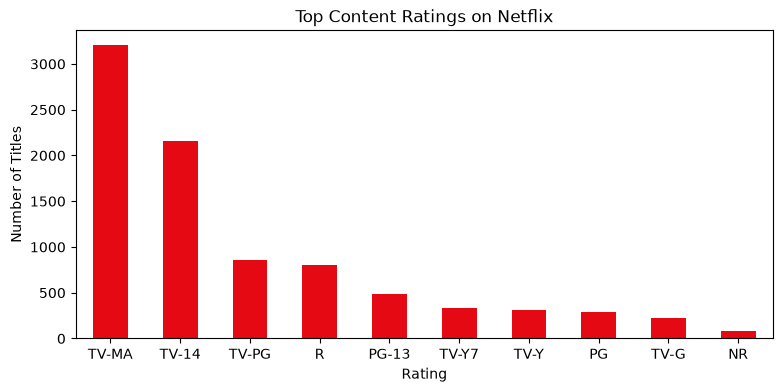

In [11]:
# Get top 10 ratings distribution
top_ratings = df['rating'].value_counts().head(10)

# Plot ratings chart
plt.figure(figsize=(9, 4))
top_ratings.plot(kind='bar', color='#E50914')
plt.title('Top Content Ratings on Netflix')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.show()